# Forecasting Sales During Promotions

A grocery chain plans its weekly promotions in advance: which products, how big a discount, what mechanic (a price cut, "2 for 1", loyalty points, a bundle), whether to advertise, whether to put the product on a display by the checkout. Each store then needs to know how many units to order. Order too few and shelves run empty; too many and stock is left over.

This notebook builds a forecast of units sold per product, store, and promotion, and compares it with what a planner would do without a model: assume it sells like the last promotions.

**Data:** synthetic, generated by [make_data.py](make_data.py): two years of promotions in 120 stores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
promos = pd.read_csv("promos.csv.gz", parse_dates=["week"])
print(f"{len(promos):,} product-store promotions, {promos.product_id.nunique()} products, {promos.store_id.nunique()} stores, "
      f"{promos.week.dt.date.min()} to {promos.week.dt.date.max()}")
promos.head()

155,288 product-store promotions, 180 products, 120 stores, 2019-01-02 to 2020-12-30


,week,product_id,category,regular_price,store_id,store_format,traffic_cluster,region,discount,mechanic,duration_days,advertised,checkout_display,units_sold
0,2019-01-02,DAI007,dairy,6.5,S089,convenience,medium,Volga,0.25,price cut,7,0,1,25
1,2019-01-02,DAI007,dairy,6.5,S048,convenience,medium,Center,0.25,price cut,7,0,0,16
2,2019-01-02,DAI007,dairy,6.5,S107,supermarket,medium,Urals,0.25,price cut,7,0,0,39
3,2019-01-02,DAI007,dairy,6.5,S019,convenience,low,Volga,0.25,price cut,7,0,0,16
4,2019-01-02,DAI007,dairy,6.5,S013,hypermarket,high,South,0.25,price cut,7,0,0,137


## 1. What drives promo sales

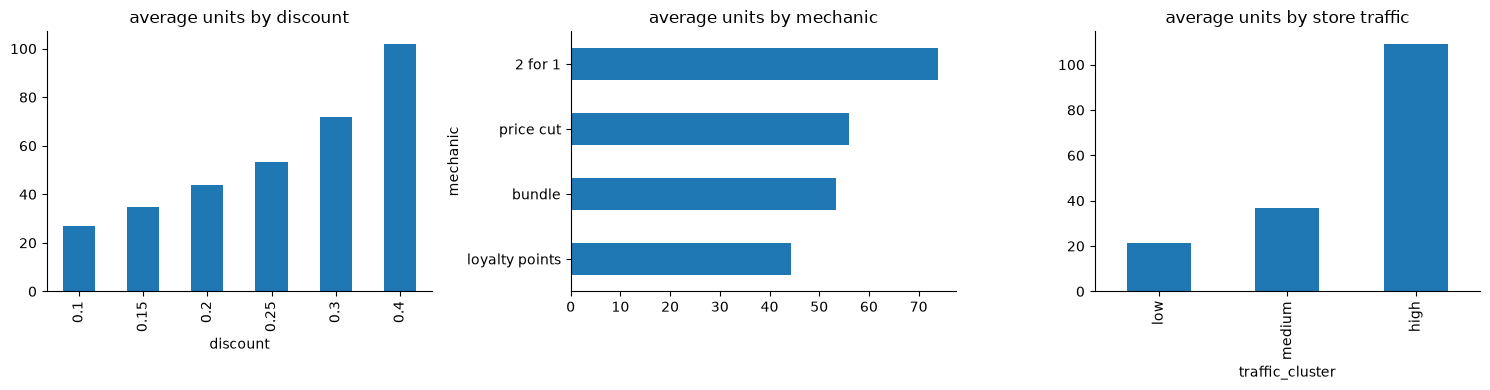

advertised: +35% average units
checkout_display: +23% average units


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
promos.groupby("discount").units_sold.mean().plot.bar(ax=axes[0], title="average units by discount")
promos.groupby("mechanic").units_sold.mean().sort_values().plot.barh(ax=axes[1], title="average units by mechanic")
promos.groupby("traffic_cluster").units_sold.mean().reindex(["low", "medium", "high"]).plot.bar(ax=axes[2], title="average units by store traffic")
plt.tight_layout()
plt.show()

for col in ["advertised", "checkout_display"]:
    means = promos.groupby(col).units_sold.mean()
    print(f"{col}: {means[1] / means[0] - 1:+.0%} average units")

These raw comparisons mix effects together (advertised promotions may also have bigger discounts, for example). The model below sorts them out.

### The March 2020 weeks

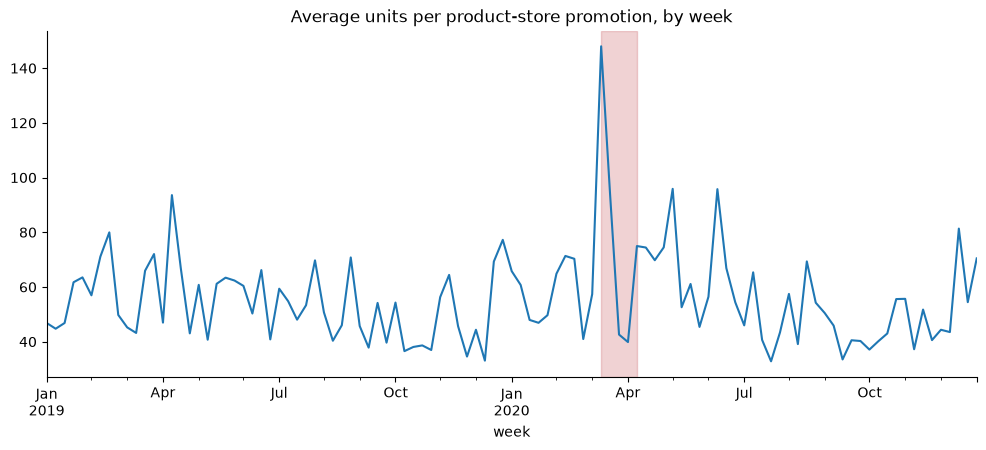

In [4]:
weekly = promos.groupby("week").units_sold.mean()
ax = weekly.plot(title="Average units per product-store promotion, by week")
ax.axvspan("2020-03-08", "2020-04-04", color="#c44e52", alpha=0.25)
plt.show()

In March 2020 people stocked up when the pandemic began, then bought less for a while. Those weeks say nothing about normal promotions, so they are left out of training, as in the original analysis.

## 2. Features

Everything the model sees is known when the promotion is planned: the plan itself, the product, the store, and how this product sold in **earlier** promotions.

In [5]:
covid = promos.week.between("2020-03-08", "2020-04-04")
data = promos[~covid].sort_values("week").copy()

# how the product and the product-store pair sold in earlier promotions (only weeks before the current one)
for keys, name in [(["product_id"], "product_history"), (["product_id", "store_id"], "pair_history")]:
    weekly_mean = data.groupby(keys + ["week"]).units_sold.mean().rename("m").reset_index()
    weekly_mean[name] = weekly_mean.groupby(keys)["m"].transform(lambda s: s.shift().expanding().mean())
    data = data.merge(weekly_mean[keys + ["week", name]], on=keys + ["week"], how="left")
store_size = data.groupby("store_id").units_sold.transform("mean") / data.units_sold.mean()
data["store_size"] = store_size        # a store's sales level relative to the average store

categorical = ["category", "store_format", "traffic_cluster", "region", "mechanic"]
for col in categorical:
    data[col] = data[col].astype("category")
features = ["discount", "mechanic", "duration_days", "advertised", "checkout_display", "regular_price", "category",
            "store_format", "traffic_cluster", "region", "product_history", "pair_history", "store_size"]
data[features + ["units_sold"]].describe(include="all").T.iloc[:, :4]

,count,unique,top,freq
discount,149302.0,NaN,NaN,NaN
mechanic,149302,4,price cut,79503
duration_days,149302.0,NaN,NaN,NaN
advertised,149302.0,NaN,NaN,NaN
checkout_display,149302.0,NaN,NaN,NaN
regular_price,149302.0,NaN,NaN,NaN
category,149302,6,snacks,26442
store_format,149302,3,convenience,84444
traffic_cluster,149302,3,high,49908
region,149302,5,South,34990


## 3. Model and baseline

The split is by time: train on everything up to September 2020 and test on October to December 2020.

**Baseline:** the product-store pair's average from earlier promotions; if the pair has never been on promotion, the product's average scaled by the store's size.

In [6]:
split = pd.Timestamp("2020-10-01")
train, test = data[data.week < split], data[data.week >= split]

model = lgb.LGBMRegressor(objective="poisson", n_estimators=600, learning_rate=0.05, num_leaves=63,
                          min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=0)
model.fit(train[features], train.units_sold)
forecast = model.predict(test[features])
baseline = test.pair_history.fillna(test.product_history * test.store_size).fillna(train.units_sold.mean())

def wape(pred):
    return np.abs(pred - test.units_sold).sum() / test.units_sold.sum()

def bias(pred):
    return pred.sum() / test.units_sold.sum() - 1

results = pd.DataFrame({"WAPE (error as share of units sold)": [wape(baseline), wape(forecast)],
                        "bias (total forecast vs. actual)": [bias(baseline), bias(forecast)]},
                       index=["earlier promotions' average", "model"])
results.round(3)

,WAPE (error as share of units sold),bias (total forecast vs. actual)
earlier promotions' average,0.648,0.095
model,0.288,0.046


WAPE is the total absolute error divided by the total units sold: a WAPE of 0.30 means the orders would be off by 30% of the volume, summed over all product-store promotions.

### Where the model gains

In [7]:
test = test.assign(forecast=forecast, baseline=baseline)
by_mechanic = test.groupby("mechanic", observed=True).apply(
    lambda d: pd.Series({"baseline WAPE": np.abs(d.baseline - d.units_sold).sum() / d.units_sold.sum(),
                         "model WAPE": np.abs(d.forecast - d.units_sold).sum() / d.units_sold.sum()}))
by_mechanic.round(3)

,baseline WAPE,model WAPE
mechanic,,
2 for 1,0.479,0.262
bundle,0.815,0.341
loyalty points,0.815,0.312
price cut,0.625,0.281


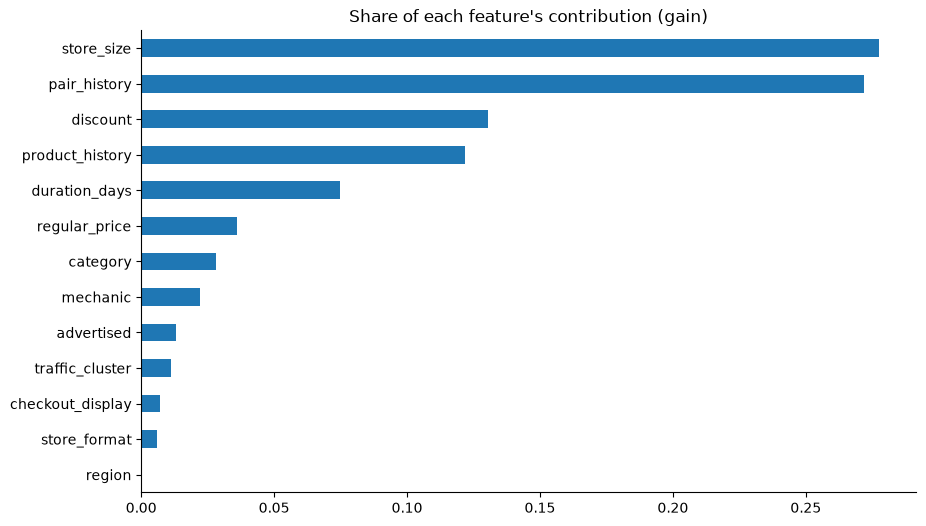

In [8]:
importance = pd.Series(model.booster_.feature_importance("gain"), index=features)
(importance / importance.sum()).sort_values().plot.barh(figsize=(10, 6), title="Share of each feature's contribution (gain)")
plt.show()

### What a planner can ask it

The model can price out choices before the promotion runs. For the test promotions, predicted units with and without advertising and a checkout display, everything else unchanged:

In [9]:
scenarios = {}
for name, changes in {"as planned": {}, "no ads, no display": {"advertised": 0, "checkout_display": 0},
                      "advertised": {"advertised": 1}, "advertised + display": {"advertised": 1, "checkout_display": 1}}.items():
    scenarios[name] = model.predict(test[features].assign(**changes)).sum()
scenarios = pd.Series(scenarios)
(scenarios / scenarios["no ads, no display"] - 1).round(3).rename("units vs. no ads and no display")

as planned              0.167
no ads, no display      0.000
advertised              0.319
advertised + display    0.544
Name: units vs. no ads and no display, dtype: float64

## Results

- Bigger discounts, "2 for 1", advertising, a checkout display, and high-traffic stores all lift promo sales. In raw averages, advertised promotions sell 35% more and those with a checkout display 23% more.
- The March 2020 weeks are left out: panic buying at the start of the pandemic, then a slump.
- On October to December 2020, the model's error is 29% of the units sold (WAPE 0.29), against 65% for the average of earlier promotions; its total is 5% above the actual, against 9.5%. The gain is largest for the less common mechanics, bundles and loyalty points, where the past average misses by over 80%.
- The model can price out choices before a promotion runs: for the test promotions it expects about 32% more units with advertising, and about 54% more with advertising plus a checkout display, than with neither.

## Tools

Python, pandas, NumPy, LightGBM, matplotlib